# Differential abundance of the ITS fungal community

**Question.** Which fungal taxa (collapsed to genus + unresolved higher ranks) change in abundance between **sampling times**?

**Design.** 18 independent samples (each from a different soil): 3 plant genera × 2 times × 3 replicates.

| Factor | Levels | Taken from the sample name |
|---|---|---|
| `plant_genus` | E, T, R | 1st letter |
| `Time` | B, F | 2nd letter |
| replicate | 1, 2, 3 | 3rd character |

*Example: sample `EF1` = genus **E**, time **F**, replicate **1**.*

**Method.** DESeq2 (Love et al. 2014) on genus-collapsed counts. Size factors are estimated with `poscounts` (suitable when many zeros remain after collapsing).

**Workflow**

1. Load libraries
2. Load ASV counts and taxonomy into a `phyloseq` object
3. Collapse ASVs to genus and prune low-count taxa
4. Fit DESeq2 models (additive vs interaction × parametric vs local)
5. Dispersion plots
6. VST + PCA (visual check of the design)
7. Time effect within each genus
8. Volcano plots
9. Reading the results


---
## 1. Setup

The packages used throughout this notebook are loaded below. phyloseq and DESeq2 are installed from Bioconductor; vegan, openxlsx, dplyr, ggplot2 and ggrepel are available from CRAN.

Bioconductor:

BiocManager::install(c("phyloseq", "DESeq2"))

CRAN:

install.packages(c("vegan", "openxlsx", "dplyr", "ggplot2", "ggrepel"))


In [1]:
library(phyloseq)
library(vegan)
library(openxlsx)
library(dplyr)
library(DESeq2)
library(ggplot2)
library(ggrepel)


Loading required package: permute


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following object is masked from ‘package:dplyr’:

    explain


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following object is masked from ‘package:dplyr’:

    combine


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, eval

---
## 2. Load the data

The Excel file has two sheets of interest: the **ASV count table** and the **taxonomy** of each ASV. Sample metadata (genus and time) is read from the sample names here.

> The `stopifnot()` line stops the notebook if any ASV is missing from the taxonomy table.


In [2]:
asv <- read.xlsx("datasets/ITS_table_200.xlsx", sheet = "ITS-table", rowNames = TRUE)
asv[] <- lapply(asv, as.numeric)

tax <- read.xlsx("datasets/ITS_table_200.xlsx", sheet = "taxonomy", rowNames = TRUE)
colnames(tax) <- c("Kingdom", "Phylum", "Class", "Order", "Family", "Genus", "Species", "Strain")
stopifnot(all(rownames(asv) %in% rownames(tax)))

ps <- phyloseq(otu_table(asv, taxa_are_rows = TRUE), tax_table(as.matrix(tax)))

sample_data(ps) <- data.frame(
  plant_genus = factor(substr(sample_names(ps), 1, 1), levels = c("E", "T", "R")),
  Time        = factor(substr(sample_names(ps), 2, 2), levels = c("B", "F")),
  row.names   = sample_names(ps))

ps


phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 7275 taxa and 18 samples ]
sample_data() Sample Data:       [ 18 samples by 2 sample variables ]
tax_table()   Taxonomy Table:    [ 7275 taxa by 8 taxonomic ranks ]

---
## 3. Genus-level collapsing and low-count filter

- `tax_glom()` sums all ASVs that belong to the same genus, so every test below is on **genus + higher ranks that did not resolve to genus**.
- `NArm = FALSE` **keeps ASVs with no genus assignment** instead of dropping them, so their reads still count toward the collapsed table.
- `prune_taxa(taxa_sums(ps) >= 10, ps)` removes taxa with fewer than 10 reads across all 18 samples. DESeq2 needs some positive counts to estimate dispersion; very rare taxa add noise.



In [3]:
ps <- tax_glom(ps, taxrank = "Genus", NArm = FALSE)
ps <- prune_taxa(taxa_sums(ps) >= 10, ps)
ps


phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 144 taxa and 18 samples ]
sample_data() Sample Data:       [ 18 samples by 2 sample variables ]
tax_table()   Taxonomy Table:    [ 144 taxa by 8 taxonomic ranks ]

---
## 4. DESeq2 models

Four DESeqDataSet objects are built and fitted so that model choice can be checked, not assumed:

| Object | Design | `fitType` |
|---|---|---|
| `dds_param` | `~ plant_genus + Time` | parametric |
| `dds_local` | `~ plant_genus + Time` | local |
| `dds_inter_param` | `~ plant_genus * Time` | parametric |
| `dds_inter_local` | `~ plant_genus * Time` | local |

- **Design.** The interaction design (`plant_genus * Time`) is the one that matches the beta-diversity result (significant genus × time interaction). The additive design is for completeness and comparison.
- **`sfType = "poscounts"`.** Size factors are estimated from positive counts only. After genus collapsing many taxa still have zeros in several samples; the default geometric-mean size-factor method fails or becomes unstable when any sample has mostly zeros for the taxa being compared.
- **`minReplicatesForReplace = Inf`.** Outlier replacement is turned off. With only 3 replicates per cell, replacing an “outlier” count would remove most of the information for that group.
- **`test = "Wald"`.** Wald tests on individual coefficients / contrasts; suitable once a single design is chosen for exploratory reporting only.


In [4]:
suppressMessages(dds_inter_param <- phyloseq_to_deseq2(ps, ~ plant_genus * Time))
suppressMessages(dds_inter_local <- phyloseq_to_deseq2(ps, ~ plant_genus * Time))
suppressMessages(dds_param       <- phyloseq_to_deseq2(ps, ~ plant_genus + Time))
suppressMessages(dds_local       <- phyloseq_to_deseq2(ps, ~ plant_genus + Time))

suppressMessages(dds_inter_param <- DESeq(dds_inter_param,
  test = "Wald",
  fitType = "parametric",
  sfType = "poscounts",
  minReplicatesForReplace = Inf))

suppressMessages(dds_inter_local <- DESeq(dds_inter_local,
  test = "Wald",
  fitType = "local",
  sfType = "poscounts",
  minReplicatesForReplace = Inf))

suppressMessages(dds_param <- DESeq(dds_param,
  test = "Wald",
  fitType = "parametric",
  sfType = "poscounts",
  minReplicatesForReplace = Inf))

suppressMessages(dds_local <- DESeq(dds_local,
  test = "Wald",
  fitType = "local",
  sfType = "poscounts",
  minReplicatesForReplace = Inf))

results(dds_inter_local)


log2 fold change (MLE): plant genusR.TimeF 
Wald test p-value: plant genusR.TimeF 
DataFrame with 144 rows and 6 columns
                                  baseMean log2FoldChange     lfcSE       stat
                                 <numeric>      <numeric> <numeric>  <numeric>
2ada98f50bd767e818ac1b1f2449170b  28310.73      -0.223093  0.580450  -0.384345
3c26096f56dd9d01c07e5c737166282d  15322.29       2.357313  4.586445   0.513974
ec202f404d3c50f5b3fbb502eccf2845  12843.40      -0.430849  0.897059  -0.480291
b8da529bdb2ee550161ee4d5670d53ac   7229.91       0.338628  1.376121   0.246074
531e437610d3233ed794060cdf179ee5  18929.22       2.095648  0.728849   2.875283
...                                    ...            ...       ...        ...
b09674ff5f62c361a1ce0d3fdd82c248  0.515308      -0.944577   7.44927 -0.1268012
b379c2759538ef9c6adb2dcd3b4f5849  0.490948      -4.864774   7.37284 -0.6598240
5b40d77bd14a12be36e101354b50573d  1.081417       0.429548   6.95596  0.0617526
fed239d080

---
## 5. Dispersion plots

`plotDispEsts()` shows the gene-wise (black), fitted (red) and final (blue) dispersions against mean count. The curve that follows the cloud of black points more closely is preferred.

- **Parametric** fit assumes a smooth mean–dispersion relationship of a fixed functional form.
- **Local** fit uses a local regression and is more flexible when the relationship is irregular (common with sparse counts).

> After inspecting the four panels, the **local** fit on the **interaction** design (`dds_inter_local`) is used for all reported contrasts. Re-run the notebook and confirm that the local curve tracks the black points better than the parametric one before treating this choice as final.


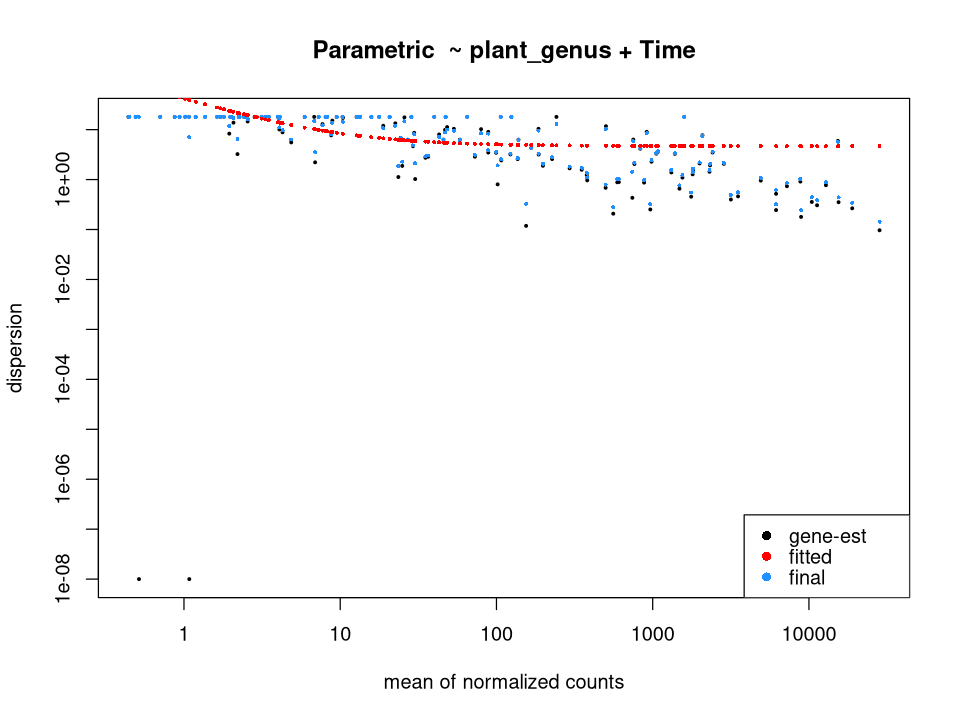

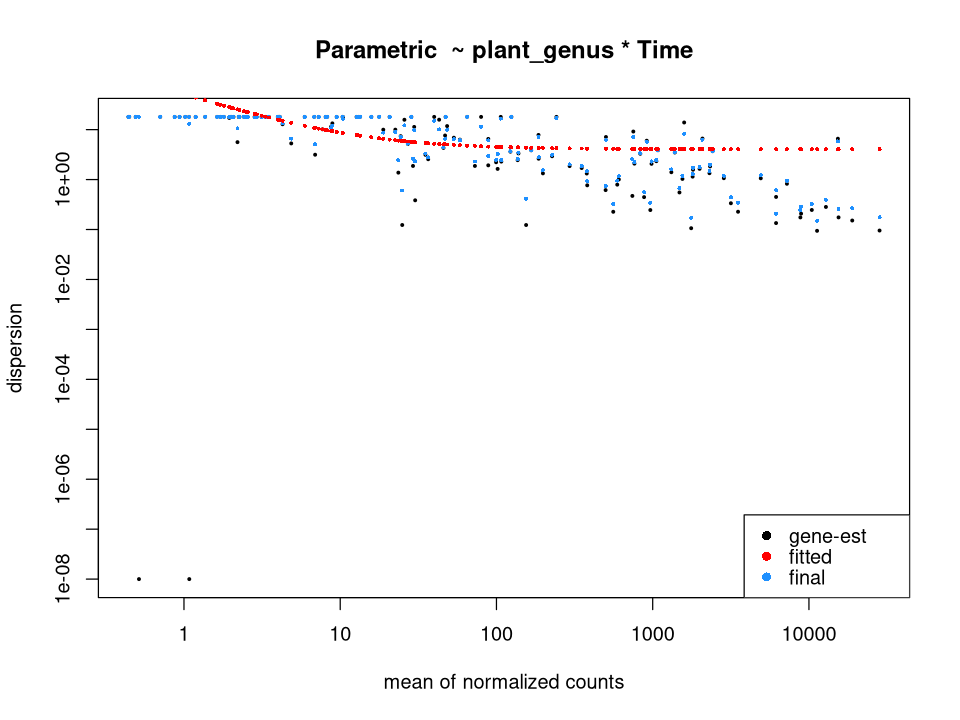

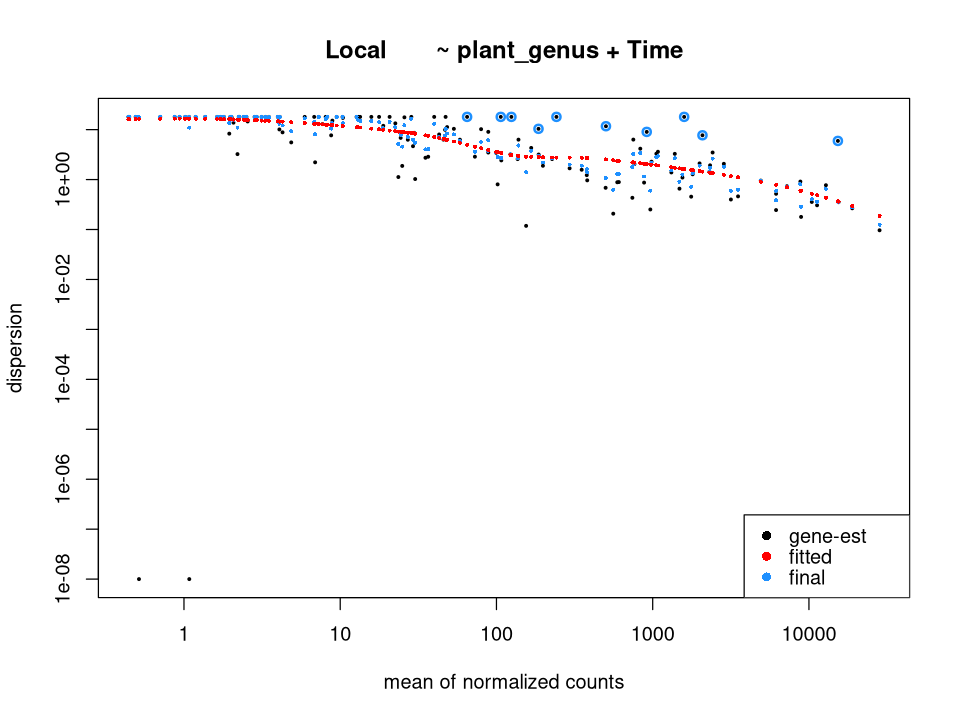

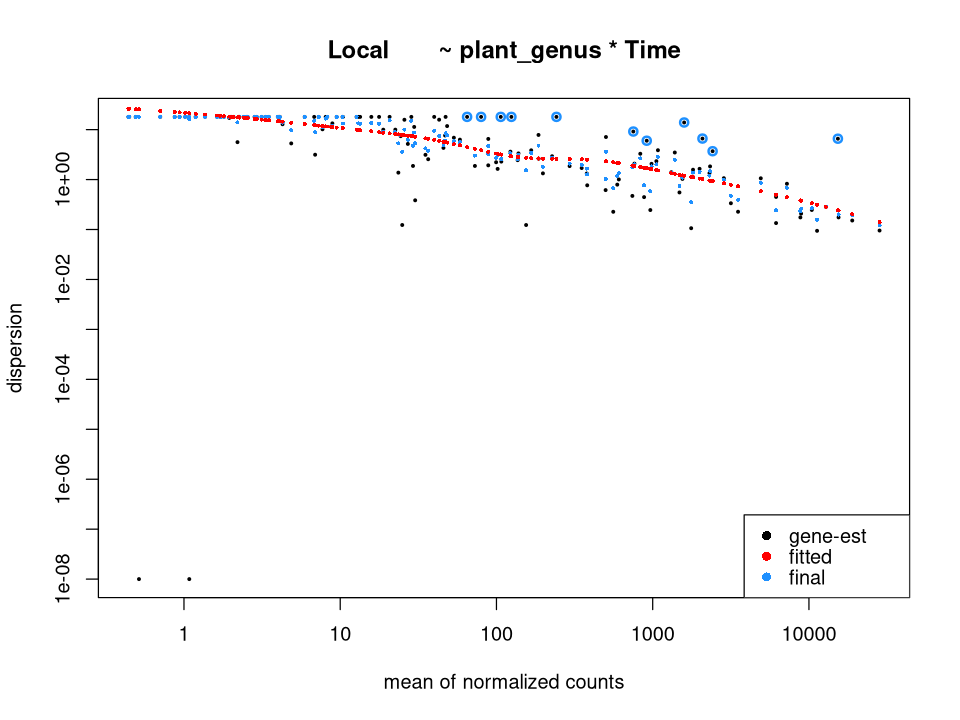

In [5]:
options(repr.plot.width = 8, repr.plot.height = 6)

plotDispEsts(dds_param,        main = "Parametric  ~ plant_genus + Time")
plotDispEsts(dds_inter_param,  main = "Parametric  ~ plant_genus * Time")
plotDispEsts(dds_local,        main = "Local       ~ plant_genus + Time")
plotDispEsts(dds_inter_local,  main = "Local       ~ plant_genus * Time")


---
## 6. VST and PCA

Variance-stabilizing transformation (VST) is applied with `blind = FALSE` so that the design used for dispersion estimation is respected. PCA on the VST matrix is only a visual check that samples separate by the factors in the model.

If the local and parametric PCAs look almost identical, the choice of `fitType` has little effect on the overall structure.


using ntop=500 top features by variance

using ntop=500 top features by variance



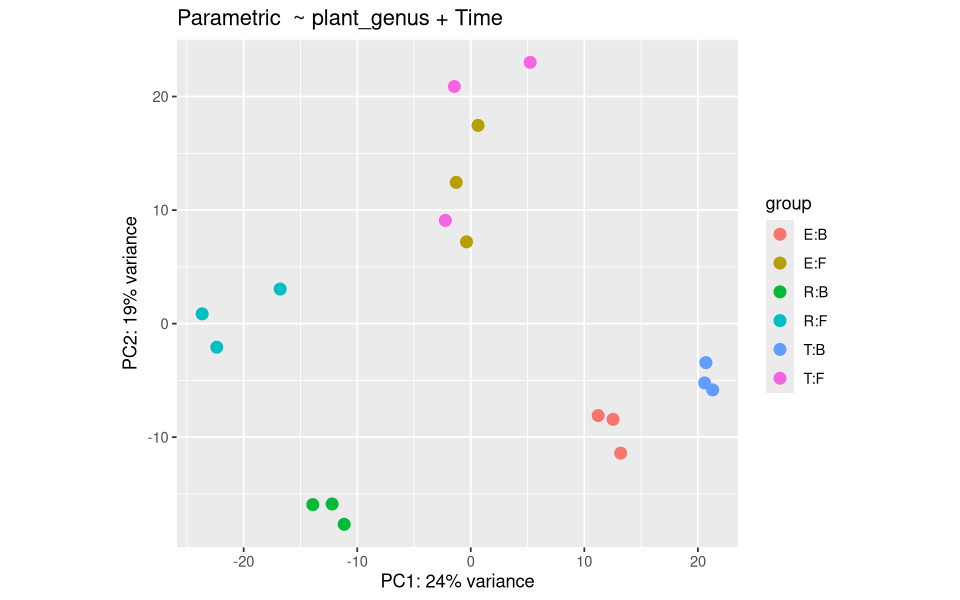

using ntop=500 top features by variance



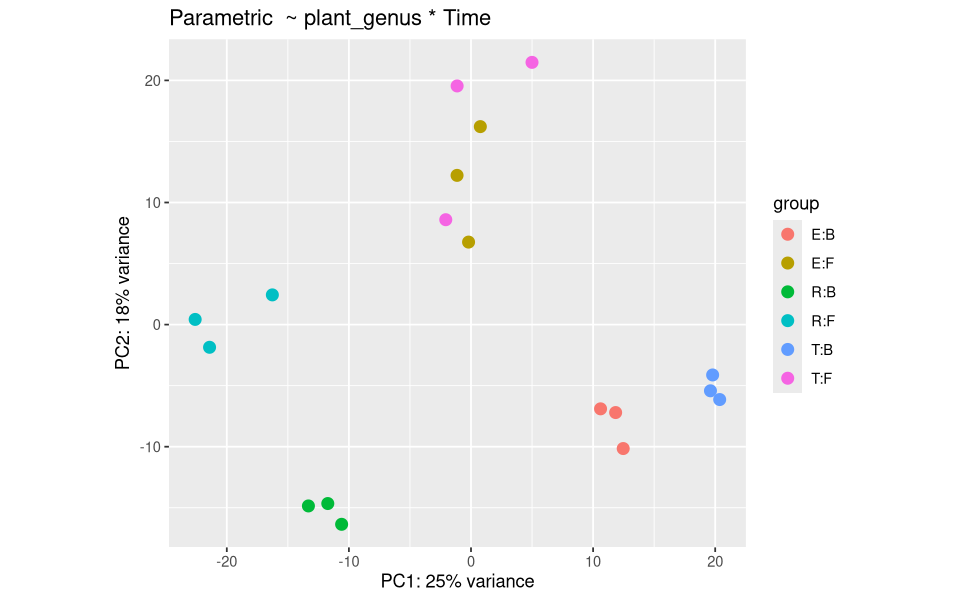

using ntop=500 top features by variance



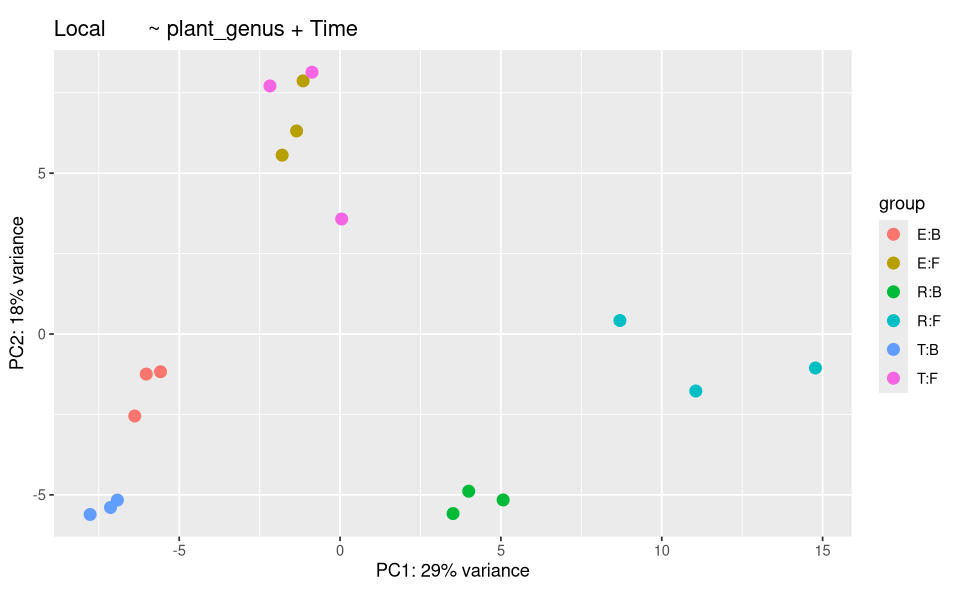

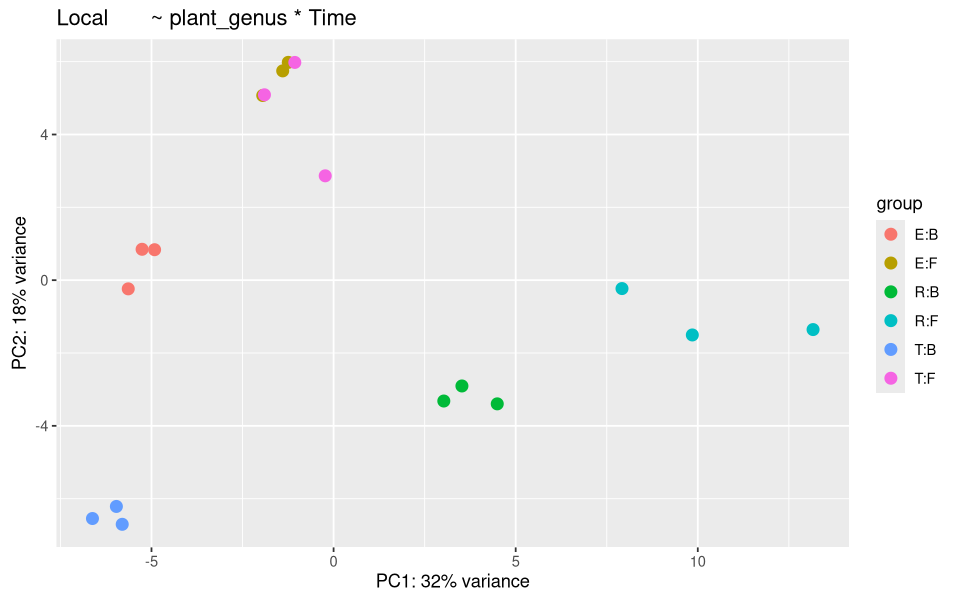

In [6]:
options(repr.plot.width = 8, repr.plot.height = 5)

vsd_param       <- varianceStabilizingTransformation(dds_param,       blind = FALSE)
vsd_inter_param <- varianceStabilizingTransformation(dds_inter_param, blind = FALSE)
vsd_local       <- varianceStabilizingTransformation(dds_local,       blind = FALSE)
vsd_inter_local <- varianceStabilizingTransformation(dds_inter_local, blind = FALSE)

plotPCA(vsd_param,       intgroup = c("plant_genus", "Time")) + ggtitle("Parametric  ~ plant_genus + Time")
plotPCA(vsd_inter_param, intgroup = c("plant_genus", "Time")) + ggtitle("Parametric  ~ plant_genus * Time")
plotPCA(vsd_local,       intgroup = c("plant_genus", "Time")) + ggtitle("Local       ~ plant_genus + Time")
plotPCA(vsd_inter_local, intgroup = c("plant_genus", "Time")) + ggtitle("Local       ~ plant_genus * Time")


---
## 7. Time effect within each genus

Because the beta-diversity analysis found a significant genus × time interaction, the time effect is extracted **inside each genus** from the interaction model (`dds_inter_local`).

With the factor coding used by DESeq2 (`plant_genus` levels E, T, R; `Time` levels B, F):

| Genus | Contrast | Meaning |
|---|---|---|
| *Euonymus* (E) | `Time_F_vs_B` | F − B in the reference genus E |
| *Tilia* (T) | `Time_F_vs_B` + `plant_genusT.TimeF` | F − B in T |
| *Rhododendron* (R) | `Time_F_vs_B` + `plant_genusR.TimeF` | F − B in R |

Positive `log2FoldChange` = higher abundance at the **final** time point; negative = higher at **baseline**.

Taxon labels are built from the deepest non-empty rank of the taxonomy table (so unresolved rows appear as e.g. `Family: ...` rather than an empty genus). Results are filtered at adjusted *p* < 0.05 (Benjamini–Hochberg) although at n=3, it should be noted that a *p* below 0.05 is not evidence of significance .


In [7]:
contr <- list(E = "Time_F_vs_B",
  T = c("Time_F_vs_B", "plant_genusT.TimeF"),
  R = c("Time_F_vs_B", "plant_genusR.TimeF"))

tax_df <- as.data.frame(tax_table(ps))
tax_df$Taxon <- apply(tax_df, 1, function(x) {
  x <- tail(x[!is.na(x) & x != ""], 1)
  paste0(names(x), ": ", x)})

sig <- bind_rows(lapply(contr, function(k) {
  r <- as.data.frame(results(dds_inter_local, contrast = list(k)))
  cbind(Taxon = tax_df[rownames(r), "Taxon"], r)
}), .id = "plant_genus") %>%
  filter(!is.na(padj), padj < 0.05) %>%
  arrange(plant_genus, log2FoldChange)

split(sig[, c("Taxon", "baseMean", "log2FoldChange", "padj")],
      factor(sig$plant_genus, levels = names(contr)))



,Taxon,baseMean,log2FoldChange,padj
,<chr>,<dbl>,<dbl>,<dbl>
5f5a379e21b058c0f756c6e2b53601b1,Genus: g__Bicornispora,915.84860,-26.630165,1.402685e-15
45c47cc9585676247d36d5909072f631...2,Genus: g__Dematiopleospora,15.82083,-17.229223,1.139194e-03
f2b1edc0c6c2811a9ce5e4bc952a92c8...3,Genus: g__Basidiomycota_gen_Incertae_sedis,106.55231,-16.814091,6.458540e-03
c744679b814424594a2d667aa3cbc4ad...4,Genus: g__Ascomycota_gen_Incertae_sedis,88.61985,-10.990429,7.224379e-05
1b1ac22dd9bf659c50d313e84dbf6059...5,Genus: g__Ramicandelaber,154.81276,-10.534729,5.160384e-07
427693e4da896ceb304d27f24c396c88...6,Genus: g__Hydropisphaera,72.79404,-8.514570,2.186383e-03
36c7f9b058b202c8443b26fa63ccd43f...7,Genus: g__Paradevriesia,227.08203,-8.137155,2.393695e-03
93d3ce3d399678415973182bdea8ff19...8,Genus: g__Darkera,29.23128,-7.975509,2.583595e-02
83e0b558de8048b66a79f7097758fd66...9,Genus: g__Seiridium,982.94623,-7.598138,4.922295e-05


---
## 8. Volcano plots

One volcano plot per genus. Points with adjusted *p* < 0.05 are coloured (firebrick = greater at final, royalblue = greater at baseline). Significant points are numbered by rank of `log2FoldChange` so they can be matched to the tables in section 7 without crowding the plot with long taxon names.


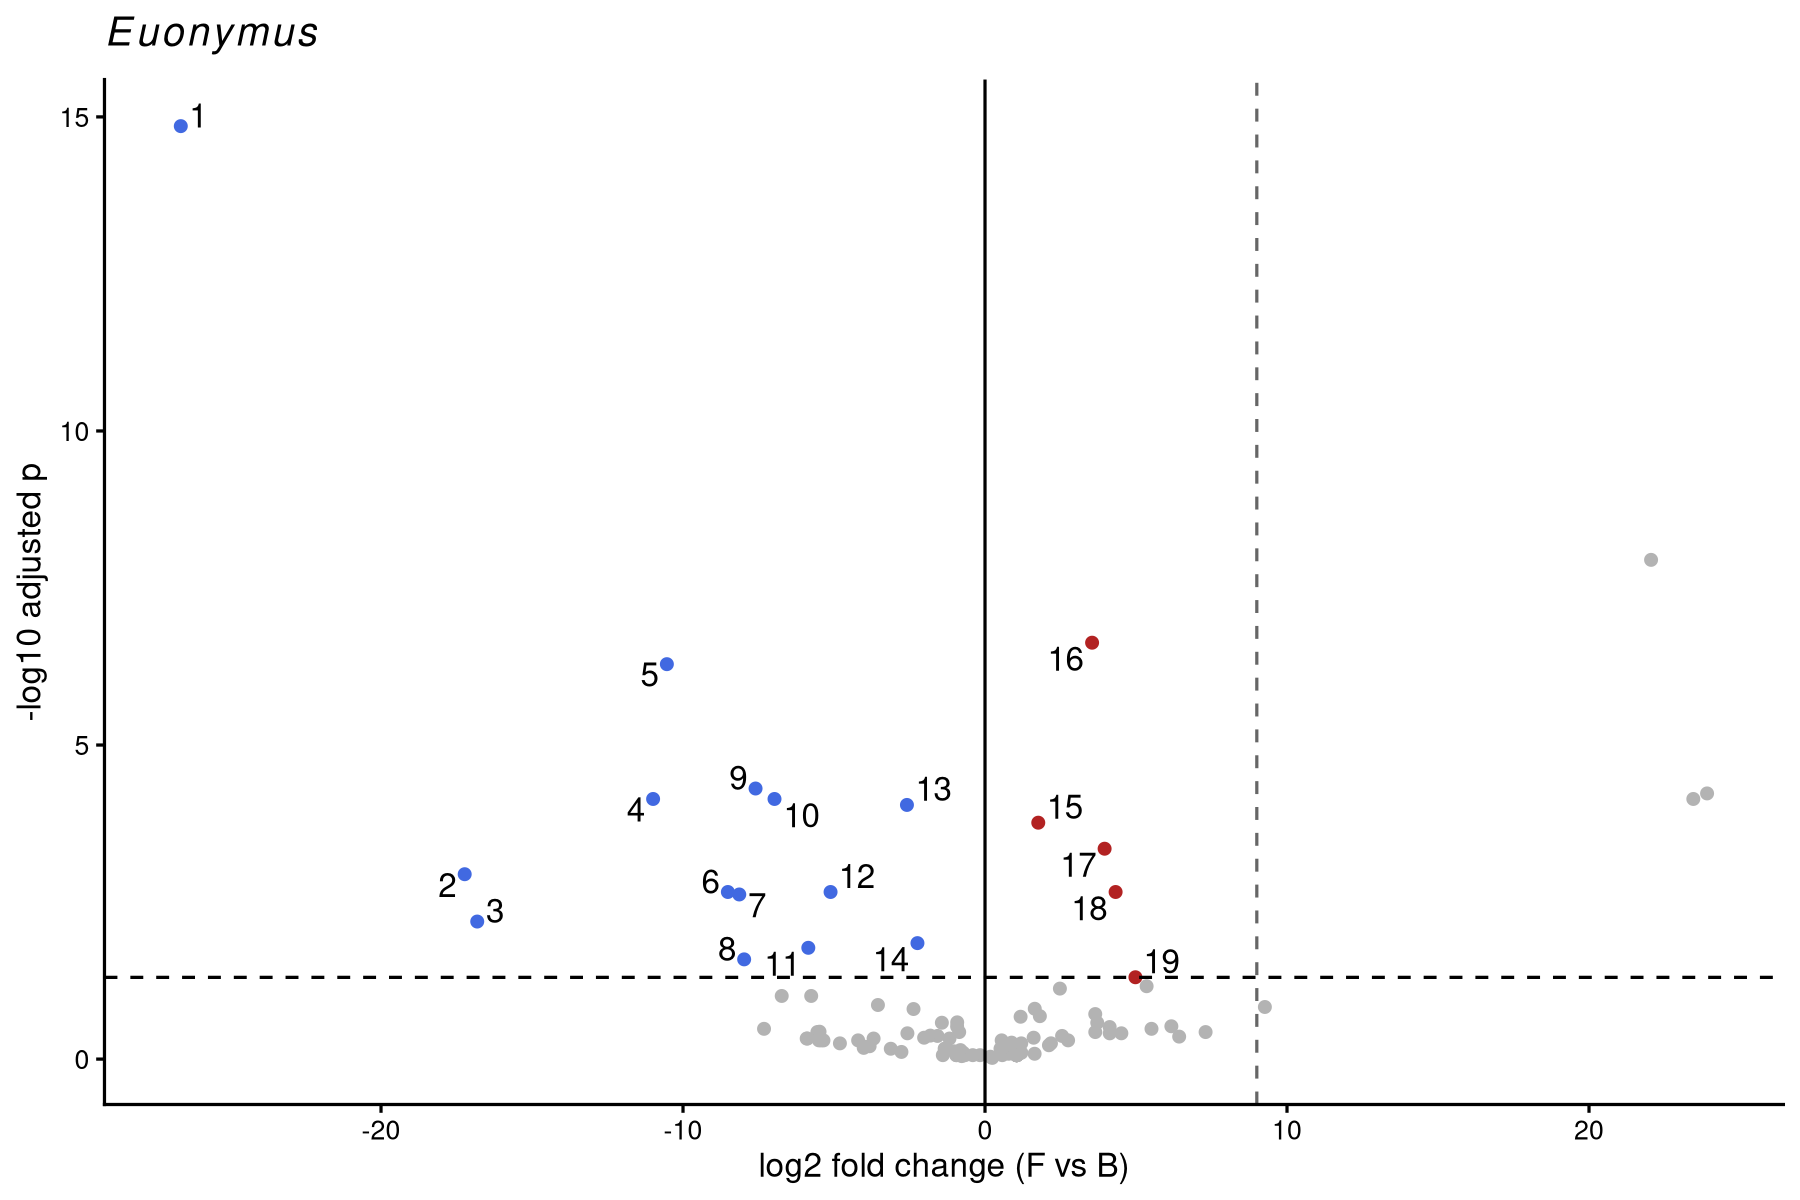

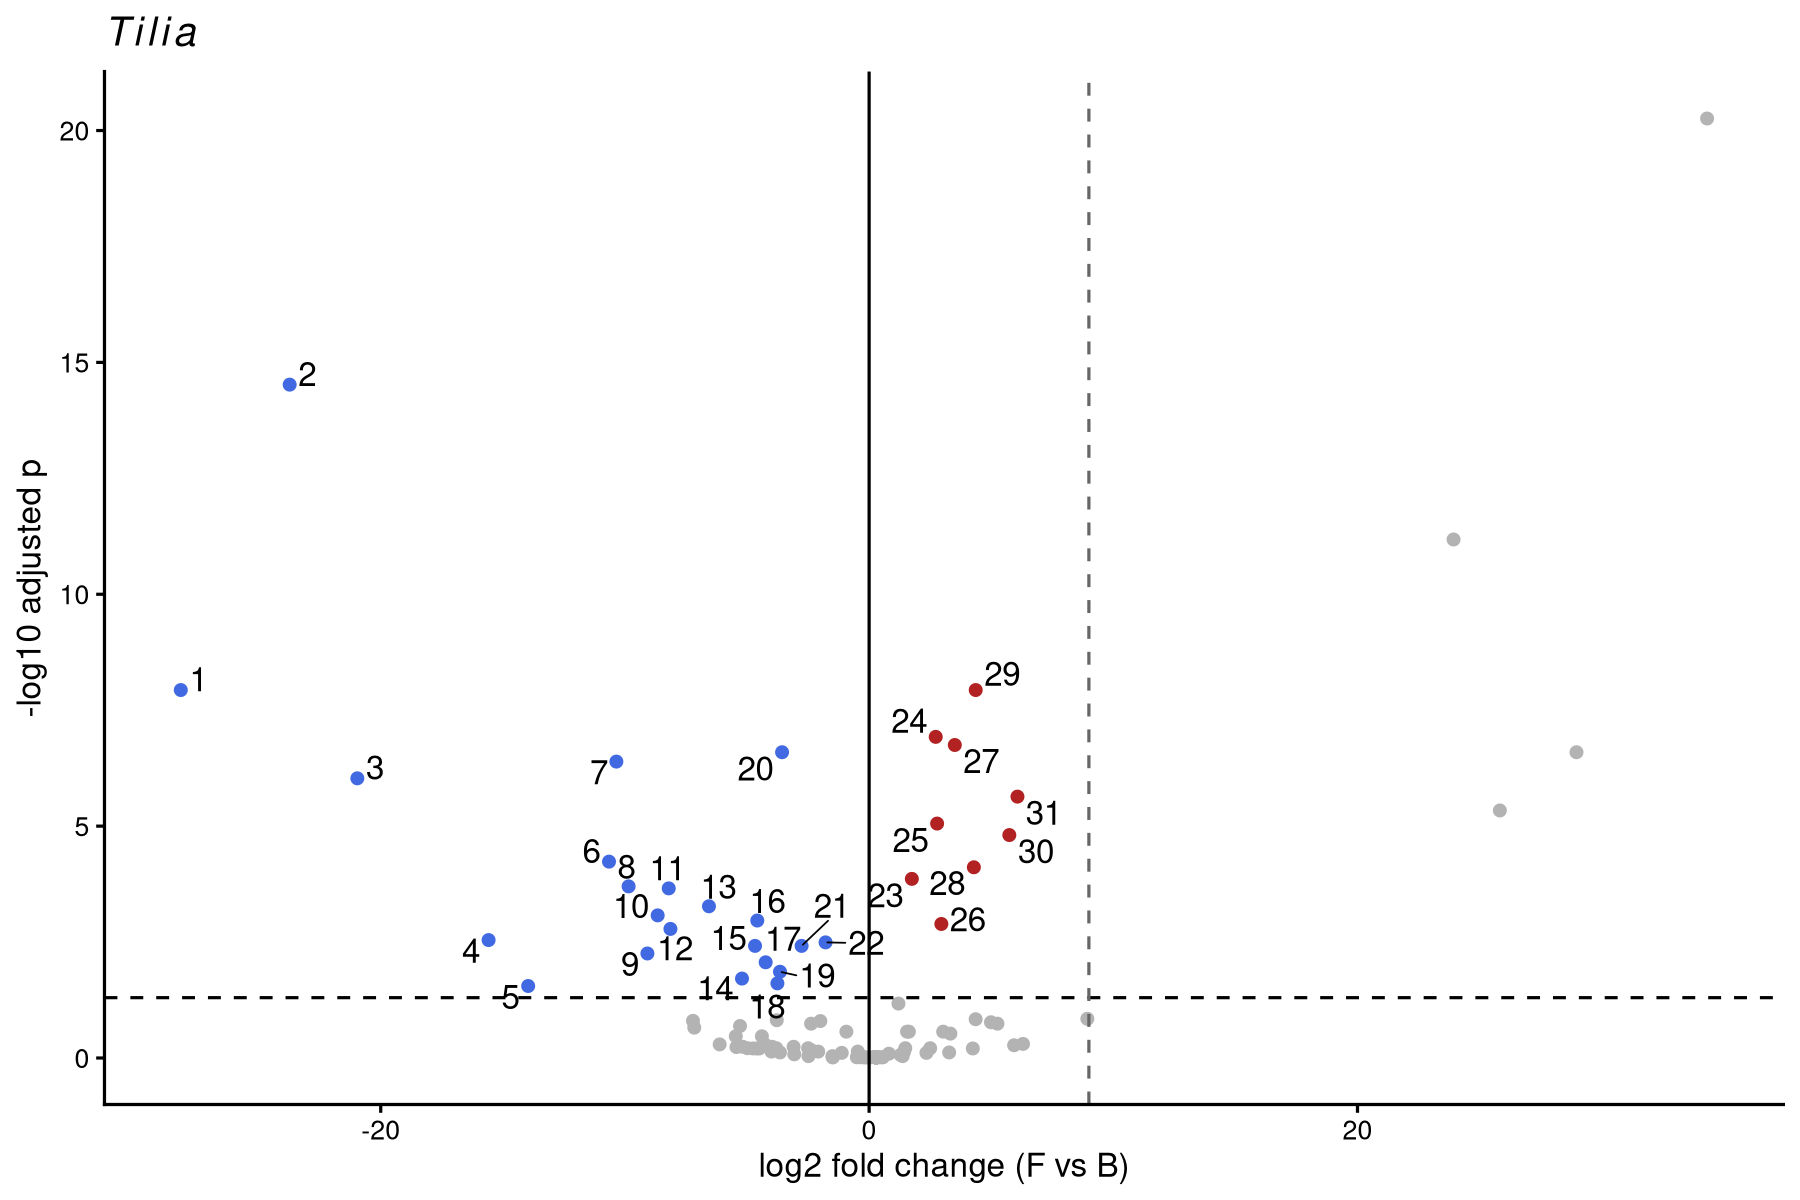

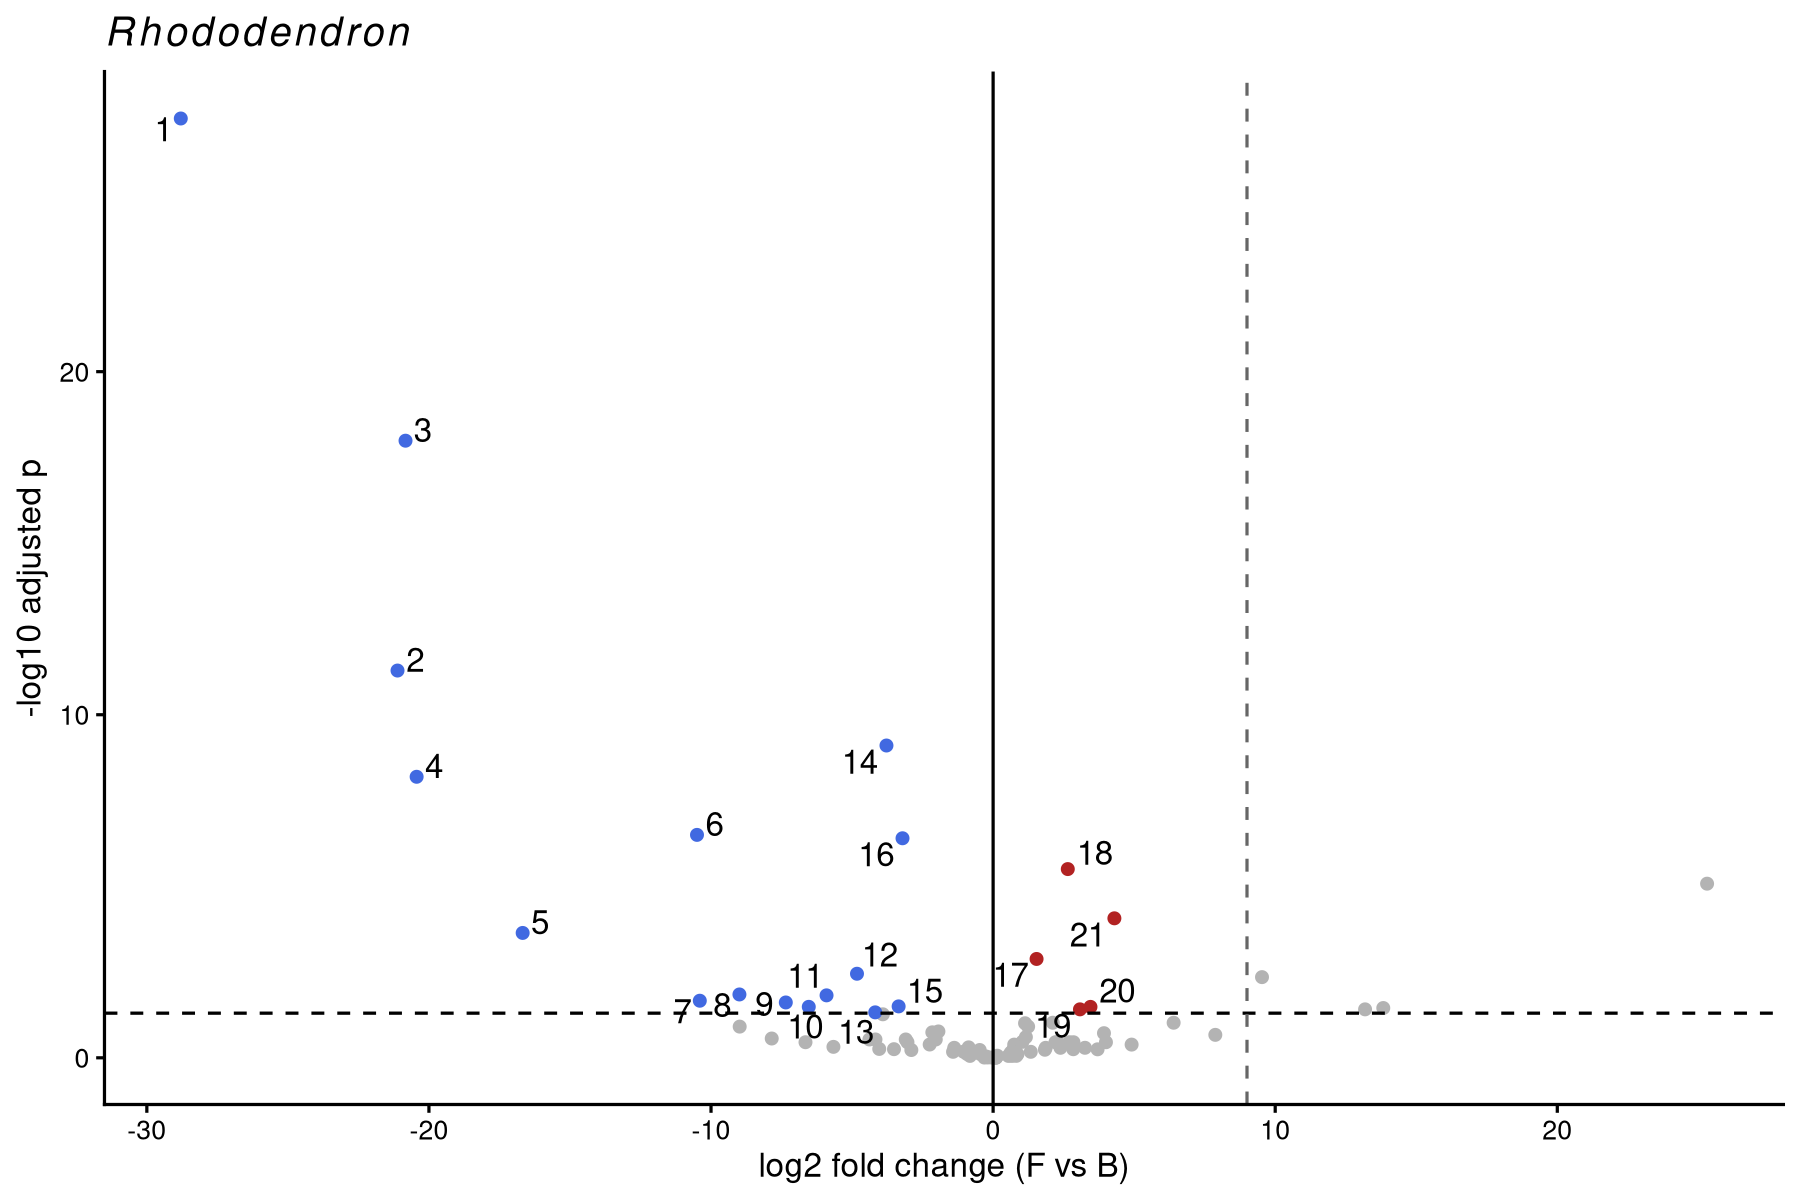

In [8]:
options(repr.plot.width = 15, repr.plot.height = 10)

volcano <- function(df, title, pos_tresh = NULL, neg_tresh = NULL) {

  sig <- !is.na(df$padj) & df$padj < 0.05


  excluded <- rep(FALSE, nrow(df))
  if (!is.null(pos_tresh)) excluded <- excluded | df$log2FoldChange > pos_tresh
  if (!is.null(neg_tresh)) excluded <- excluded | df$log2FoldChange < neg_tresh
  excluded[is.na(excluded)] <- FALSE

  show <- sig & !excluded

  df$group <- ifelse(show, ifelse(df$log2FoldChange > 0, "up", "down"), "ns")

  df$num <- rank(ifelse(show, df$log2FoldChange, NA),
                 na.last = "keep", ties.method = "first")

  p <- ggplot(df, aes(log2FoldChange, -log10(padj), colour = group)) +
    geom_point(na.rm = TRUE) +
    geom_text_repel(aes(label = num), size = 7, colour = "black",
                    max.overlaps = Inf, na.rm = TRUE) +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed") +
    geom_vline(xintercept = 0) +
    scale_colour_manual(values = c(up = "firebrick", down = "royalblue", ns = "grey70")) +
    labs(title = title, x = "log2 fold change (F vs B)", y = "-log10 adjusted p") +
    theme_classic(base_size = 20) +
    theme(legend.position = "none")# +
    #coord_cartesian(ylim = c(0, 35))

  if (!is.null(pos_tresh)) p <- p + geom_vline(xintercept = pos_tresh, linetype = "dashed", colour = "grey40")
  if (!is.null(neg_tresh)) p <- p + geom_vline(xintercept = neg_tresh, linetype = "dashed", colour = "grey40")

  p
}

# full results (all taxa) for each contrast, reusing contr and tax_df from the previous cell
res_list <- lapply(contr, function(k) {
  r <- as.data.frame(results(dds_inter_local, contrast = list(k)))
  r$Taxon <- tax_df[rownames(r), "Taxon"]
  r
})

res_E <- res_list$E
res_T <- res_list$T
res_R <- res_list$R


volcano(res_E, expression(italic(Euonymus)), pos_tresh = 9)
volcano(res_T, expression(italic(Tilia)), pos_tresh = 9)
volcano(res_R, expression(italic(Rhododendron)), pos_tresh = 9)



---
## 9. Reading the results

**In short:** the interaction model is preferred (genus × time was significant in the beta-diversity PERMANOVA), so time effects are reported **within each genus**. The local dispersion fit is preferred when the mean–dispersion cloud is irregular. Only taxa with adjusted *p* < 0.05 are analysed as differentially abundant; with n = 3 per cell the list should be read as exploratory support for the community-level pattern, not as a definitive species-level claim.

### Model choice

* **Interaction vs additive.** Beta diversity showed a significant `plant_genus:Time` term. An additive DESeq2 model would force a single time effect shared by all genera and would misrepresent taxa whose change is genus-specific. All reported fold changes therefore come from `dds_inter_local`.
* **Local vs parametric.** Compare the four `plotDispEsts` panels. If the local red curve tracks the black points more closely, keep `fitType = "local"`. If the two curves are almost the same, the choice has little practical impact; the notebook still reports the local interaction model for consistency with the dispersion check.
* **`poscounts` and no outlier replacement.** Both choices are deliberate for sparse, low-replicate counts.

### How to read the contrast tables

* `log2FoldChange` > 0 → taxon is more abundant at **final (F)** than at **baseline (B)** in that genus.
* `log2FoldChange` < 0 → taxon is more abundant at **baseline**.
* `baseMean` is the average of the normalized counts across all samples used in the model; very low `baseMean` taxa that still reach significance should be treated with extra caution.
* `padj` is BH-adjusted *p-value* for completeness and should not be treated as evidence.
* With three replicates per cell, dispersion estimates are noisy and power is low. Non-significant taxa are not evidence of no change, and significant taxa are not evidence of change either. This analysis is exploratory.



---
### References

* Love, M.I., Huber, W. & Anders, S. Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2. Genome Biol 15, 550 (2014). https://doi.org/10.1186/s13059-014-0550-8
* McMurdie PJ, Holmes S (2013) phyloseq: An R Package for Reproducible Interactive Analysis and Graphics of Microbiome Census Data. PLOS ONE 8(4): e61217. https://doi.org/10.1371/journal.pone.0061217

